In [1]:
# 필요한 패키지가 없다면 다음 줄의 주석을 해제하고 먼저 실행하세요.
# %pip install numpy pandas matplotlib scikit-learn threadpoolctl
import hashlib, io, json, os, sys, zipfile
from pathlib import Path
from urllib.request import urlopen
# 단일 스레드 실행에 맞추어 joblib의 CPU 탐색도 제한한다.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import matplotlib
from IPython.display import display, Image
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
    recall_score, f1_score, brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve)
from threadpoolctl import threadpool_limits
SEED = 42
OUT = Path('weather_results')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.grid':True, 'grid.alpha':.20, 'font.size':10})
NAVY, TEAL, AMBER = '#173B5F', '#198478', '#C47622'

def show_table(name, table):
    table.to_csv(OUT / f'{name}.csv', encoding='utf-8-sig')
    display(table.round(4))

def save_plot(fig, name):
    p = OUT / f'{name}.png'
    fig.savefig(p, dpi=170, bbox_inches='tight', facecolor='white')
    display(Image(filename=str(p)))
    plt.close(fig)


## 1 서론
오늘의 관측이 끝난 시점에 내일 강수 여부를 추정한다. ① 월별 강수 패턴은 어떤가 ② 계절 정보와 최근 관측은 얼마나 유용한가 ③ 7개 모델은 단순 기준선을 얼마나 개선하는가 ④ 위음성과 위양성의 가중치가 달라지면 오류가 어떻게 변하는가를 조사한다. 다음 날의 실제 강수량·최고기온·최저기온은 입력에 포함하지 않는다.


## 2 데이터셋 소개
- Kaggle: [Rachael Tatman, Did it rain in Seattle? (1948–2017)](https://www.kaggle.com/datasets/rtatman/did-it-rain-in-seattle-19482017)
- 관측소 정보: [NOAA NCEI Seattle Tacoma Airport, USW00024233](https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:USW00024233/detail)
- DATE: 관측 날짜, PRCP: 일강수량(인치), TMAX·TMIN: 일최고·최저기온(°F), RAIN: 강수 여부. 분석 그래프에서는 강수량을 mm, 온도를 °C로 변환한다. 


In [2]:
DATA_FILE = Path('seattleWeather_1948-2017.csv')
DOWNLOAD = 'https://www.kaggle.com/api/v1/datasets/download/rtatman/did-it-rain-in-seattle-19482017'
if not DATA_FILE.exists():
    try:
        with urlopen(DOWNLOAD, timeout=45) as response:
            archive_bytes = response.read()
        with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
            DATA_FILE.write_bytes(archive.read(DATA_FILE.name))
    except Exception as exc:
        raise RuntimeError('Kaggle에서 CSV를 내려받아 작업 폴더에 놓고 다시 실행하세요.') from exc
checksum = hashlib.sha256(DATA_FILE.read_bytes()).hexdigest()
raw = pd.read_csv(DATA_FILE)
raw['DATE'] = pd.to_datetime(raw['DATE'], format='%Y-%m-%d')
raw['RAIN'] = raw['RAIN'].astype('string').str.lower().map({'true':1, 'false':0})
raw = raw.sort_values('DATE').reset_index(drop=True)
assert raw['DATE'].is_unique, '중복 날짜를 확인하세요.'
assert raw['DATE'].diff().iloc[1:].eq(pd.Timedelta(days=1)).all(), '날짜 공백을 확인하세요.'
observed = raw[['PRCP','RAIN']].notna().all(axis=1)
assert raw.loc[observed,'PRCP'].gt(0).eq(raw.loc[observed,'RAIN']).all()
assert raw['PRCP'].dropna().ge(0).all()
reversed_temperature = raw.TMAX.lt(raw.TMIN)
quality = {'rows':len(raw),'columns':raw.shape[1],'first':str(raw.DATE.min().date()),
           'last':str(raw.DATE.max().date()),'sha256':checksum,'missing':raw.isna().sum().to_dict(),
           'missing_dates':raw.loc[raw.RAIN.isna(),'DATE'].dt.strftime('%Y-%m-%d').tolist(),
           'wet':int(raw.RAIN.eq(1).sum()),'dry':int(raw.RAIN.eq(0).sum()),
           'temperature_zero':int(raw.TMIN.eq(0).sum()),
           'reversed_temperature_dates':raw.loc[reversed_temperature,'DATE'].dt.strftime('%Y-%m-%d').tolist()}
print(json.dumps(quality, ensure_ascii=False, indent=2))
display(raw.head())
# 최저보다 낮은 최고기온은 원값을 추정할 근거가 없어 두 온도만 결측 처리한다.
clean = raw.copy()
clean.loc[reversed_temperature, ['TMAX','TMIN']] = np.nan
weather = clean.set_index('DATE').assign(
    precip_mm=lambda d:d.PRCP*25.4, max_c=lambda d:(d.TMAX-32)*5/9,
    min_c=lambda d:(d.TMIN-32)*5/9, range_c=lambda d:(d.TMAX-d.TMIN)*5/9)


,DATE,PRCP,TMAX,TMIN,RAIN
0,1948-01-01,0.47,51,42,1.0
1,1948-01-02,0.59,45,36,1.0
2,1948-01-03,0.42,45,35,1.0
3,1948-01-04,0.31,45,34,1.0
4,1948-01-05,0.17,45,32,1.0


{
  "rows": 25551,
  "columns": 5,
  "first": "1948-01-01",
  "last": "2017-12-14",
  "sha256": "f2024bd654ebf3de1007882ae511f7f61ce00aac12dc450469938cfa3b928f78",
  "missing": {
    "DATE": 0,
    "PRCP": 3,
    "TMAX": 0,
    "TMIN": 0,
    "RAIN": 3
  },
  "missing_dates": [
    "1998-06-02",
    "1998-06-03",
    "2005-09-05"
  ],
  "wet": 10900,
  "dry": 14648,
  "temperature_zero": 1,
  "reversed_temperature_dates": [
    "1951-11-20"
  ]
}


## 3 탐색적 데이터 분석
훈련 종료일인 2007년 12월 31일까지의 관측값으로 월별 강수일 비율, 강수량 분포, 기온 분포 및 연속일 관계를 살펴본다. 월별 비율의 분모는 해당 월의 유효 `RAIN` 기록이다. 일강수량이 0인 날과 값이 없는 날을 구별한다. 연속일 관측에는 자기상관이 있으므로 독립 표본 검정의 p값 대신 비율과 차이의 크기를 제시한다.


,count,mean,std,min,25%,50%,75%,max
precip_mm,21912.0,2.6642,6.0239,0.0000,0.0000,0.0000,2.5400,127.5080
max_c,21914.0,15.1991,7.0526,-8.8889,10.0000,14.4444,20.5556,37.7778
min_c,21914.0,6.8181,4.9101,-17.7778,3.3333,6.6667,10.5556,20.5556
range_c,21914.0,8.3809,3.8064,0.5556,5.5556,7.7778,11.1111,23.3333


,valid,wet,wet_rate,mean_mm
month,,,,
1,1860,1125.0,0.6048,4.7303
2,1695,929.0,0.5481,3.6255
3,1860,1016.0,0.5462,3.0470
4,1800,834.0,0.4633,2.1514
5,1860,657.0,0.3532,1.4344
6,1798,542.0,0.3014,1.2369
7,1860,310.0,0.1667,0.6278
8,1860,363.0,0.1952,0.8801
9,1799,522.0,0.2902,1.4746


next_rain,0,1
RAIN,,
0,9440,3176
1,3177,6116


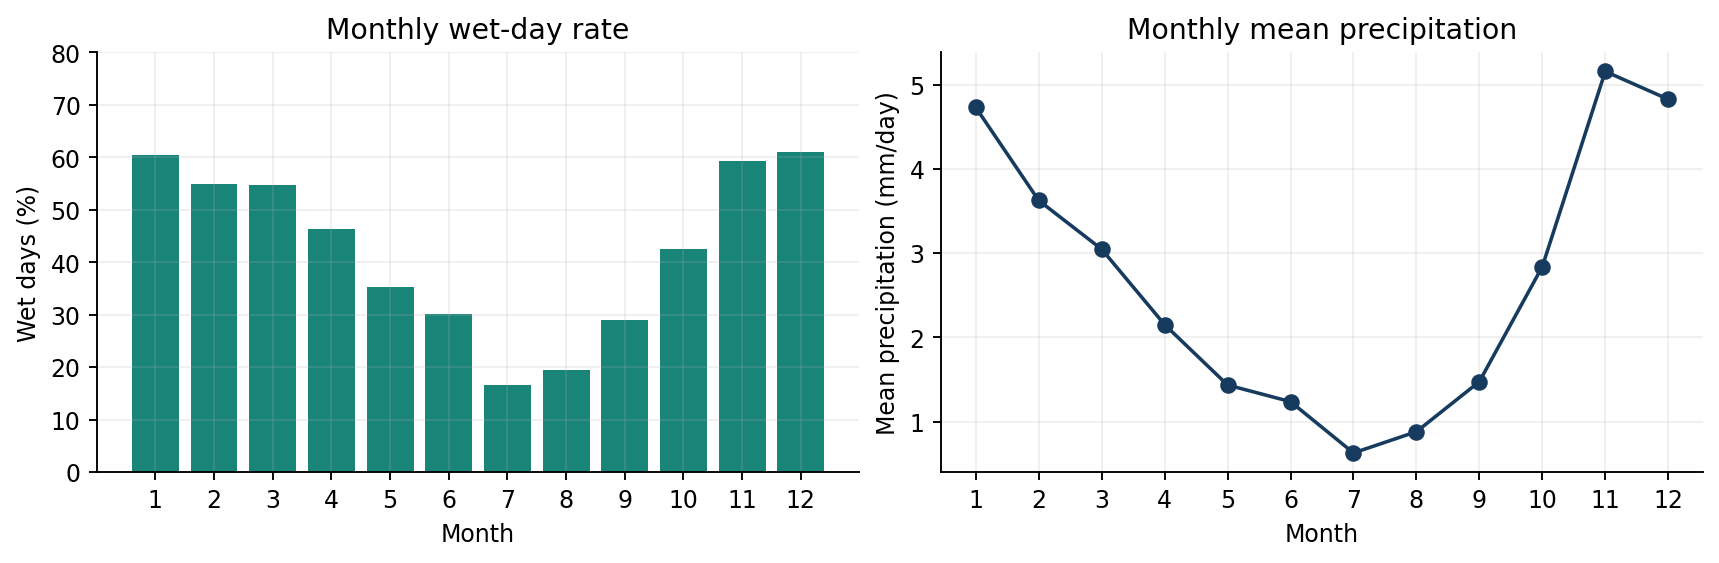

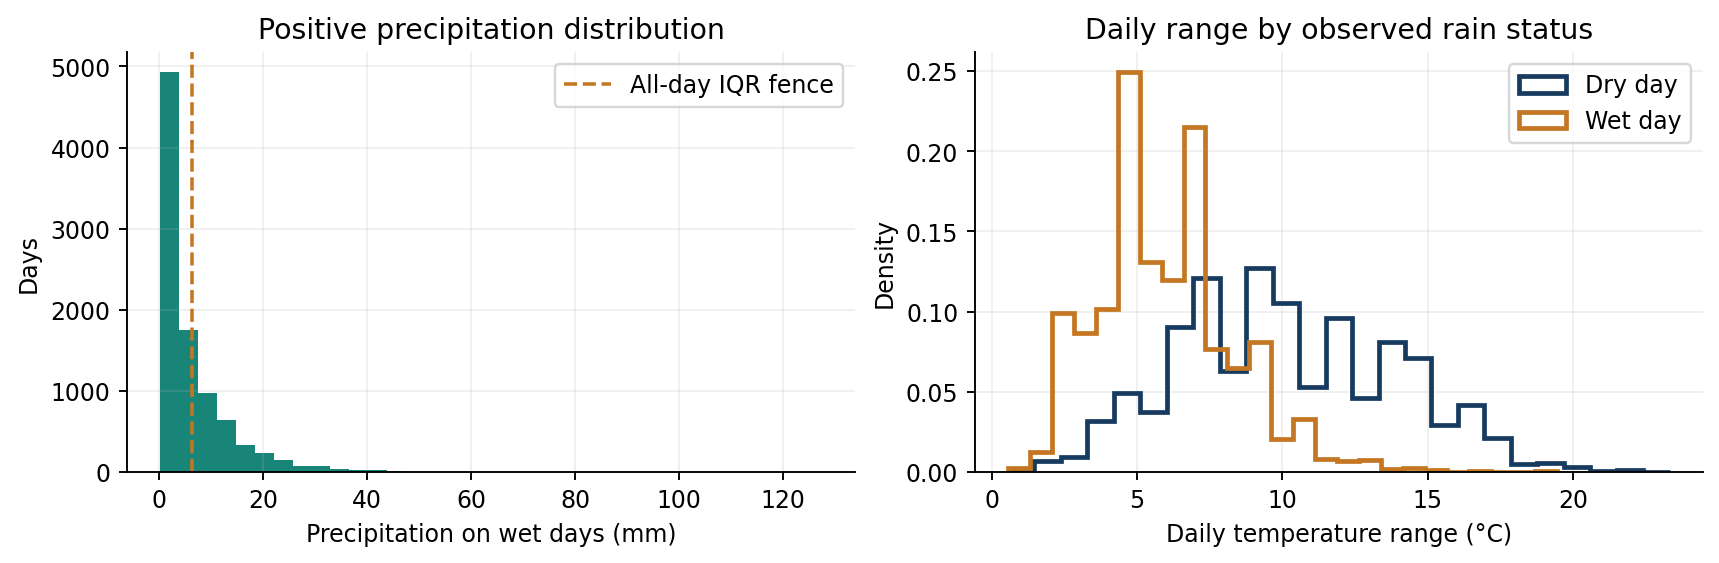

,precip_mm,max_c,min_c,range_c,next_rain
precip_mm,1.0000,-0.2282,-0.0645,-0.3396,0.2988
max_c,-0.2282,1.0000,0.8571,0.7472,-0.3153
min_c,-0.0645,0.8571,1.0000,0.2981,-0.1784
range_c,-0.3396,0.7472,0.2981,1.0000,-0.3540
next_rain,0.2988,-0.3153,-0.1784,-0.3540,1.0000


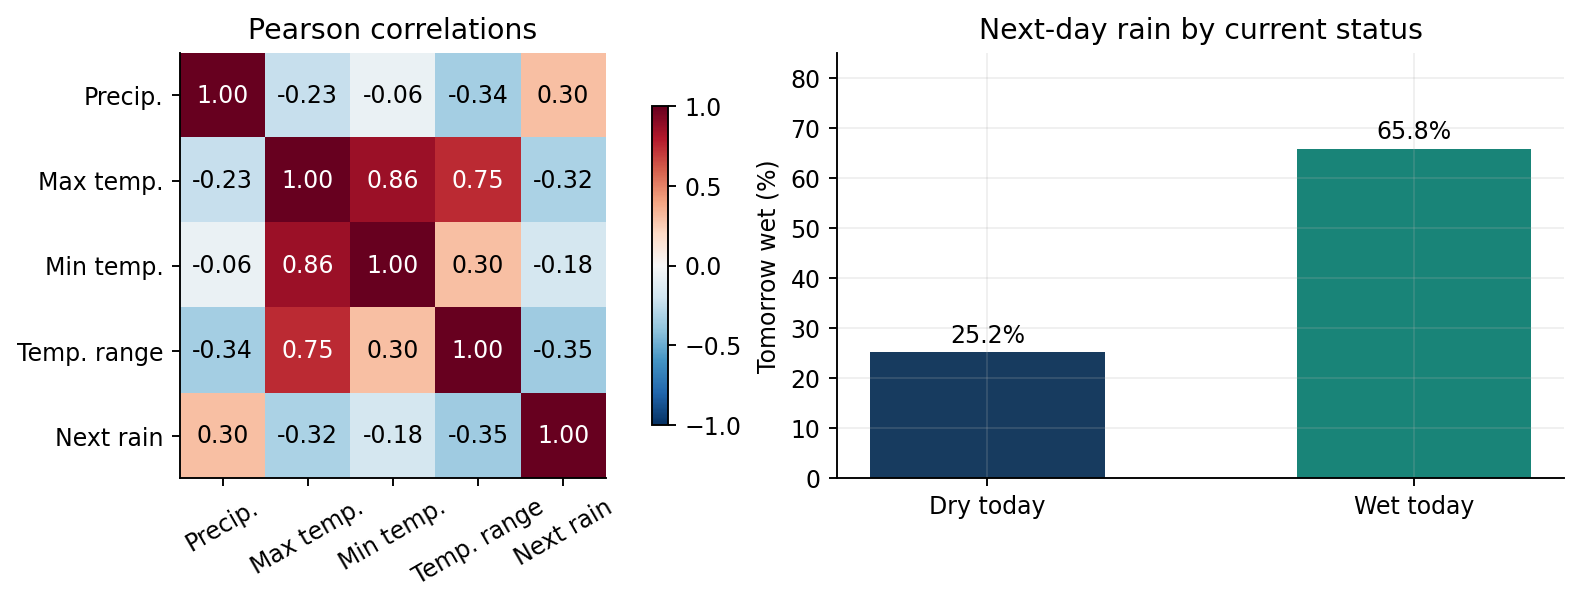

{'zero': 12619, 'upper_fence': 6.35, 'above_fence': 3019, 'max_mm': 127.50799999999998, 'max_date': '2003-10-20'}


In [3]:
eda = weather.loc[:'2007-12-31'].copy()
eda['month'] = eda.index.month
eda['next_rain'] = eda.RAIN.shift(-1)
measurements = ['precip_mm','max_c','min_c','range_c']
show_table('descriptive', eda[measurements].describe().T)
monthly = eda.groupby('month').agg(valid=('RAIN','count'), wet=('RAIN','sum'),
    wet_rate=('RAIN','mean'), mean_mm=('precip_mm','mean'))
show_table('monthly', monthly)
transition = pd.crosstab(eda.RAIN, eda.next_rain).reindex(index=[0,1],columns=[0,1])
show_table('transition', transition)
next_rate = transition[1] / transition.sum(axis=1)
q1, q3 = eda.precip_mm.quantile([.25,.75]); fence = q3 + 1.5*(q3-q1)
tail = {'zero':int(eda.precip_mm.eq(0).sum()),'upper_fence':float(fence),
        'above_fence':int(eda.precip_mm.gt(fence).sum()),'max_mm':float(eda.precip_mm.max()),
        'max_date':str(eda.precip_mm.idxmax().date())}
print(tail)
fig, ax = plt.subplots(1,2,figsize=(10,3.2),layout='constrained')
ax[0].bar(monthly.index,100*monthly.wet_rate,color=TEAL); ax[0].set(xticks=range(1,13),ylabel='Wet days (%)',xlabel='Month',title='Monthly wet-day rate',ylim=(0,80))
ax[1].plot(monthly.index,monthly.mean_mm,'o-',color=NAVY); ax[1].set(xticks=range(1,13),ylabel='Mean precipitation (mm/day)',xlabel='Month',title='Monthly mean precipitation')
save_plot(fig,'fig01_month')
fig, ax = plt.subplots(1,2,figsize=(10,3.2),layout='constrained')
ax[0].hist(eda.loc[eda.precip_mm.gt(0),'precip_mm'],bins=35,color=TEAL);ax[0].axvline(fence,color=AMBER,ls='--',label='All-day IQR fence');ax[0].legend();ax[0].set(xlabel='Precipitation on wet days (mm)',ylabel='Days',title='Positive precipitation distribution')
for y,c,name in [(0,NAVY,'Dry day'),(1,AMBER,'Wet day')]:
    ax[1].hist(eda.loc[eda.RAIN.eq(y),'range_c'],bins=25,density=True,histtype='step',linewidth=2,color=c,label=name)
ax[1].legend();ax[1].set(xlabel='Daily temperature range (°C)',ylabel='Density',title='Daily range by observed rain status')
save_plot(fig,'fig02_distribution')
correlations = eda[measurements+['next_rain']].corr()
show_table('correlations',correlations)
fig, ax = plt.subplots(1,2,figsize=(10,3.45),layout='constrained')
mat=ax[0].imshow(correlations,cmap='RdBu_r',vmin=-1,vmax=1)
labels=['Precip.','Max temp.','Min temp.','Temp. range','Next rain']
ax[0].set(xticks=range(5),yticks=range(5),xticklabels=labels,yticklabels=labels,title='Pearson correlations');ax[0].tick_params(axis='x',rotation=30);ax[0].grid(False)
for i in range(5):
    for j in range(5): ax[0].text(j,i,f'{correlations.iloc[i,j]:.2f}',ha='center',va='center',color='white' if abs(correlations.iloc[i,j])>.65 else 'black')
fig.colorbar(mat,ax=ax[0],shrink=.75)
ax[1].bar(['Dry today','Wet today'],100*next_rate,color=[NAVY,TEAL],width=.55)
for i,v in enumerate(next_rate): ax[1].text(i,v*100+2,f'{100*v:.1f}%',ha='center')
ax[1].set(ylabel='Tomorrow wet (%)',title='Next-day rain by current status',ylim=(0,85))
save_plot(fig,'fig03_relation')


## 4 데이터 전처리 및 방법론
행의 날짜는 예측을 발행하는 날이다. 목표 날짜를 하루 앞으로 이동한 뒤 그 날짜로 분할한다. 오늘과 어제의 관측, 최근 3일·7일의 강수량과 강수일 비율, 최근 3일 평균 일교차, 내일의 연간 주기 사인·코사인을 사용한다. `shift(1)`은 어제, `rolling`은 오늘까지의 기록을 뜻한다. 검증 시작 이후에도 매일 새로운 오늘 관측이 들어온다고 가정하므로 이전 검증일의 실제 관측은 이후 날의 예측에 사용 가능하다. 다음 날 강수 기록이 비어 있으면 목표 행을 제외한다. 예측 변수의 빈 값은 각 훈련 폴드 중앙값으로 대체한다.

1983–1987, 1988–1992, 1993–1997, 1998–2002, 2003–2007년을 검증 구간으로 두고, 각 구간 시작 이전의 자료만 훈련에 사용한다. 최종 보류 기간은 2008-01-01부터 2017-12-14까지이다. 모델 선택 지표는 5개 검증 구간의 평균 ROC-AUC이며, 각 구간에는 동일 가중치를 준다.


In [4]:
dates = weather.index + pd.Timedelta(days=1)
year_length = np.where(dates.is_leap_year,366,365)
angle = 2*np.pi*(dates.dayofyear-1)/year_length
features = pd.DataFrame({'target_date':dates,'y':weather.RAIN.shift(-1).to_numpy(),
    'season_sin':np.sin(angle),'season_cos':np.cos(angle)},index=weather.index)
for column in ['precip_mm','max_c','min_c','range_c']:
    features[f'{column}_today'] = weather[column]
features['rain_today'] = weather.RAIN
features['precip_mm_yesterday'] = weather.precip_mm.shift(1)
for window in [3,7]:
    features[f'precip_mm_sum_{window}d'] = weather.precip_mm.rolling(window,min_periods=window).sum()
    features[f'rain_rate_{window}d'] = weather.RAIN.rolling(window,min_periods=window).mean()
features['temp_range_mean_3d'] = weather.range_c.rolling(3,min_periods=3).mean()
features = features.dropna(subset=['y']).copy()
features['y'] = features.y.astype(int)
all_cols = features.columns.drop(['y','target_date']).tolist()
calendar = ['season_sin','season_cos']
current = calendar + ['precip_mm_today','max_c_today','min_c_today','range_c_today','rain_today']
train = features[features.target_date.lt('2008-01-01')]
test = features[features.target_date.ge('2008-01-01')]
assert train.target_date.max() < test.target_date.min()
folds=[]
for year in [1983,1988,1993,1998,2003]:
    tr = np.flatnonzero(train.target_date.dt.year.lt(year))
    va = np.flatnonzero(train.target_date.dt.year.between(year,year+4))
    assert train.iloc[tr].target_date.max() < train.iloc[va].target_date.min()
    folds.append((tr,va))
show_table('splits',pd.DataFrame([{'train_end':str(train.iloc[a].target_date.max().date()),'valid_start':str(train.iloc[b].target_date.min().date()),'valid_end':str(train.iloc[b].target_date.max().date()),'train_n':len(a),'valid_n':len(b)} for a,b in folds]))
print('훈련 및 테스트 크기:', len(train), len(test), '입력 수:',len(all_cols))
models={
    'Logistic Regression': LogisticRegression(C=1,max_iter=500),
    'Decision Tree': DecisionTreeClassifier(max_depth=5,min_samples_leaf=80,random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=140,max_depth=9,min_samples_leaf=20,n_jobs=1,random_state=SEED),
    'Extra Trees': ExtraTreesClassifier(n_estimators=140,max_depth=10,min_samples_leaf=20,n_jobs=1,random_state=SEED),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=15,learning_rate=.06,early_stopping=False,random_state=SEED),
    'AdaBoost': AdaBoostClassifier(n_estimators=100,learning_rate=.5,random_state=SEED),
    'MLP': MLPClassifier(hidden_layer_sizes=(24,12),alpha=.02,max_iter=210,tol=.0005,n_iter_no_change=20,random_state=SEED)
}
def make_model(name):
    return make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),clone(models[name]))

def validate(name, cols):
    scores=[]
    predicted=np.full(len(train),np.nan)
    for a,b in folds:
        fit=make_model(name).fit(train.iloc[a][cols],train.iloc[a].y)
        prob=fit.predict_proba(train.iloc[b][cols])[:,1]
        predicted[b]=prob
        scores.append(roc_auc_score(train.iloc[b].y,prob))
    return scores,predicted

cv_scores, cv_predictions = {}, {}
with threadpool_limits(limits=1):
    for name in models:
        cv_scores[name],cv_predictions[name]=validate(name,all_cols)
cv = pd.DataFrame(cv_scores,index=['1983–87','1988–92','1993–97','1998–02','2003–07']).T
cv['Mean AUC']=cv.mean(axis=1);cv['SD']=cv.iloc[:,:5].std(axis=1)
cv=cv.sort_values('Mean AUC',ascending=False)
chosen=cv.index[0]
show_table('cv',cv)
print('교차검증 선택 모델:',chosen)


,train_end,valid_start,valid_end,train_n,valid_n
0,1982-12-31,1983-01-01,1987-12-31,12783,1826
1,1987-12-31,1988-01-01,1992-12-31,14609,1827
2,1992-12-31,1993-01-01,1997-12-31,16436,1826
3,1997-12-31,1998-01-01,2002-12-31,18262,1824
4,2002-12-31,2003-01-01,2007-12-31,20086,1825


,1983–87,1988–92,1993–97,1998–02,2003–07,Mean AUC,SD
MLP,0.7866,0.7782,0.7865,0.7738,0.7806,0.7811,0.0055
Hist Gradient Boosting,0.7818,0.7785,0.7893,0.7744,0.7801,0.7808,0.0055
Random Forest,0.7805,0.7786,0.7897,0.7737,0.7806,0.7806,0.0058
Extra Trees,0.7808,0.7748,0.7847,0.7697,0.7784,0.7777,0.0057
Logistic Regression,0.7810,0.7740,0.7804,0.7734,0.7770,0.7771,0.0035
AdaBoost,0.7698,0.7703,0.7826,0.7722,0.7741,0.7738,0.0052
Decision Tree,0.7677,0.7680,0.7878,0.7690,0.7760,0.7737,0.0086


훈련 및 테스트 크기: 21911 3636 입력 수: 13
교차검증 선택 모델: MLP


## 5 실험 결과
기준선은 항상 비가 오지 않는다고 분류하는 방식과, 오늘의 강수 상태가 내일도 이어진다고 분류하는 방식으로 정했다. 지속성 기준선의 ROC-AUC·AP는 0/1 점수의 순위 성능이다. 일반 분류는 0.5 임계값을 적용한다. Brier 점수는 예측 점수와 0/1 관측 결과의 평균 제곱오차이다. 0과 1의 점수만 내는 기준선에서는 분류 오류율과 같다.


,AUC,AP,Accuracy,Precision,Recall,Specificity,F1,Brier,TN,FP,FN,TP
MLP,0.7939,0.7364,0.7263,0.7035,0.6584,0.7802,0.6802,0.1835,1583.0,446.0,549.0,1058.0
Hist Gradient Boosting,0.7954,0.7348,0.7222,0.7057,0.6372,0.7896,0.6697,0.1834,1602.0,427.0,583.0,1024.0
Random Forest,0.7924,0.7282,0.7222,0.7010,0.6478,0.7812,0.6734,0.1847,1585.0,444.0,566.0,1041.0
Extra Trees,0.7900,0.7231,0.7239,0.6974,0.6627,0.7723,0.6796,0.1864,1567.0,462.0,542.0,1065.0
Logistic Regression,0.7863,0.7289,0.7239,0.7064,0.6422,0.7886,0.6728,0.1872,1600.0,429.0,575.0,1032.0
AdaBoost,0.7895,0.7268,0.7189,0.7085,0.6185,0.7984,0.6605,0.1878,1620.0,409.0,613.0,994.0
Decision Tree,0.7837,0.7104,0.7225,0.7085,0.6322,0.7940,0.6682,0.1879,1611.0,418.0,591.0,1016.0
Persistence,0.7145,0.6051,0.7184,0.6814,0.6814,0.7477,0.6814,0.2816,1517.0,512.0,512.0,1095.0
Always dry,0.5000,0.4420,0.5580,0.0000,0.0000,1.0000,0.0000,0.4420,2029.0,0.0,1607.0,0.0


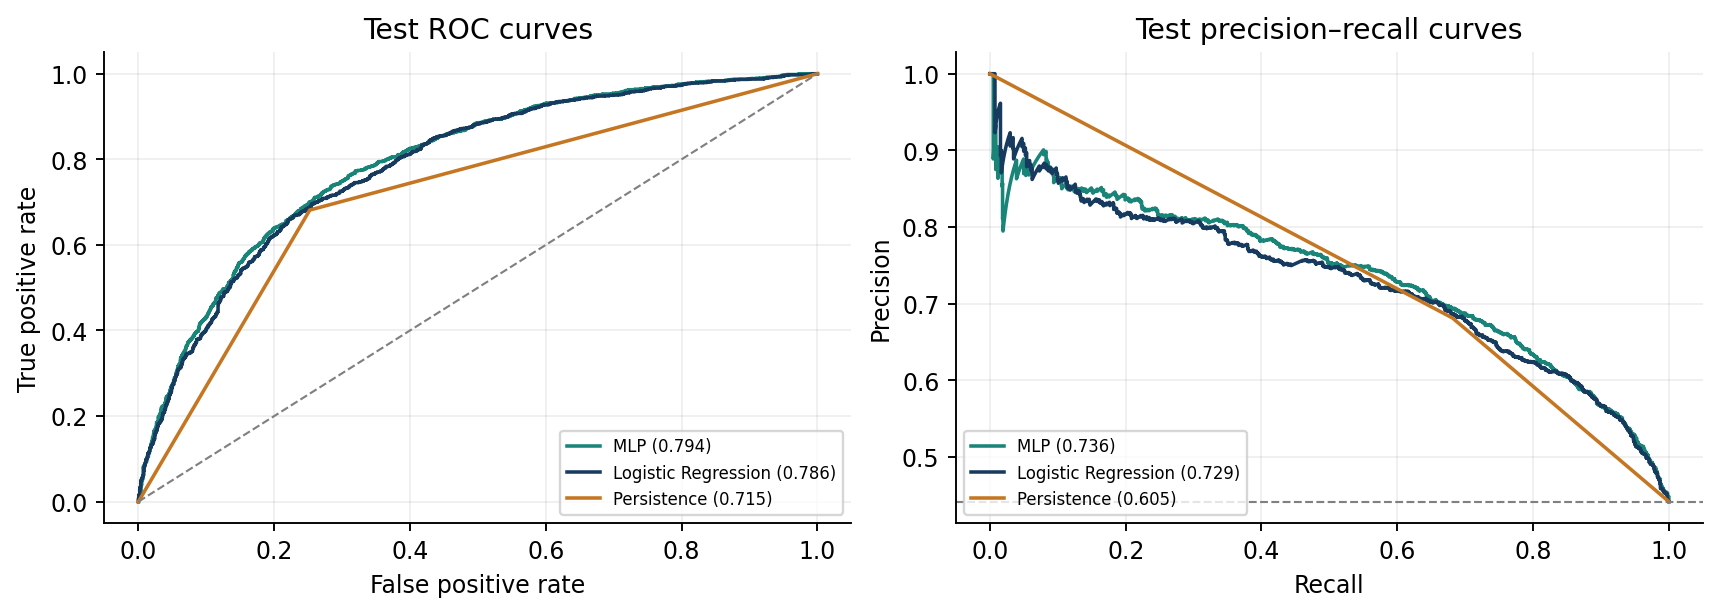

In [5]:
def evaluate(y, score, threshold=.5):
    pred=np.asarray(score)>=threshold
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(AUC=roc_auc_score(y,score),AP=average_precision_score(y,score),
        Accuracy=accuracy_score(y,pred),Precision=precision_score(y,pred,zero_division=0),
        Recall=recall_score(y,pred,zero_division=0),Specificity=tn/(tn+fp),F1=f1_score(y,pred),
        Brier=brier_score_loss(y,score),TN=int(tn),FP=int(fp),FN=int(fn),TP=int(tp))
fits,probabilities={},{}
with threadpool_limits(limits=1):
    for name in cv.index:
        fits[name]=make_model(name).fit(train[all_cols],train.y)
        probabilities[name]=fits[name].predict_proba(test[all_cols])[:,1]
probabilities['Persistence']=test.rain_today.fillna(0).to_numpy()
probabilities['Always dry']=np.zeros(len(test))
results=pd.DataFrame({k:evaluate(test.y,v) for k,v in probabilities.items()}).T
show_table('test',results)
fig, ax=plt.subplots(1,2,figsize=(10,3.5),layout='constrained')
for name in dict.fromkeys([chosen,'Logistic Regression','Persistence']):
    p=probabilities[name]; color={chosen:TEAL,'Persistence':AMBER}.get(name,NAVY)
    x,y,_=roc_curve(test.y,p);ax[0].plot(x,y,label=f'{name} ({results.loc[name,"AUC"]:.3f})',color=color)
    precision,recall,_=precision_recall_curve(test.y,p);ax[1].plot(recall,precision,label=f'{name} ({results.loc[name,"AP"]:.3f})',color=color)
ax[0].plot([0,1],[0,1],'--',color='gray',lw=.9);ax[0].set(xlabel='False positive rate',ylabel='True positive rate',title='Test ROC curves')
ax[1].axhline(test.y.mean(),ls='--',color='gray',lw=.9);ax[1].set(xlabel='Recall',ylabel='Precision',title='Test precision–recall curves')
for a in ax:a.legend(fontsize=7,loc='lower right' if a is ax[0] else 'lower left')
save_plot(fig,'fig04_curves')


### 5 추가 검증
재현율과 위양성 사이의 교환 관계를 확인하기 위해 위음성 비용을 2, 위양성 비용을 1로 가정한다. 검증 구간의 폴드 밖 점수에 0.05~0.95 후보를 대입해 비용이 가장 적은 값을 선택한다. 동률이면 0.5에 가까운 값을 선택하고 그래도 같으면 낮은 값을 택한다. 테스트 AUC의 불확실성은 30일 길이의 순환 블록 부트스트랩으로 추정한다. 파생 특징 효과는 같은 검증 구간에서 로지스틱 회귀의 세 입력 집합을 비교한다. 중요도는 선택 모델에서 변수군을 한 번에 하나씩 제거하여 같은 5개 구간에서 평균 AUC가 얼마나 줄어드는지 평가한다.


,AUC,AP,Accuracy,Precision,Recall,Specificity,F1,Brier,TN,FP,FN,TP,Cost (2FN+FP)
0.50,0.7939,0.7364,0.7263,0.7035,0.6584,0.7802,0.6802,0.1835,1583.0,446.0,549.0,1058.0,1544.0
0.37 OOF,0.7939,0.7364,0.7203,0.6572,0.7673,0.6831,0.7080,0.1835,1386.0,643.0,374.0,1233.0,1391.0


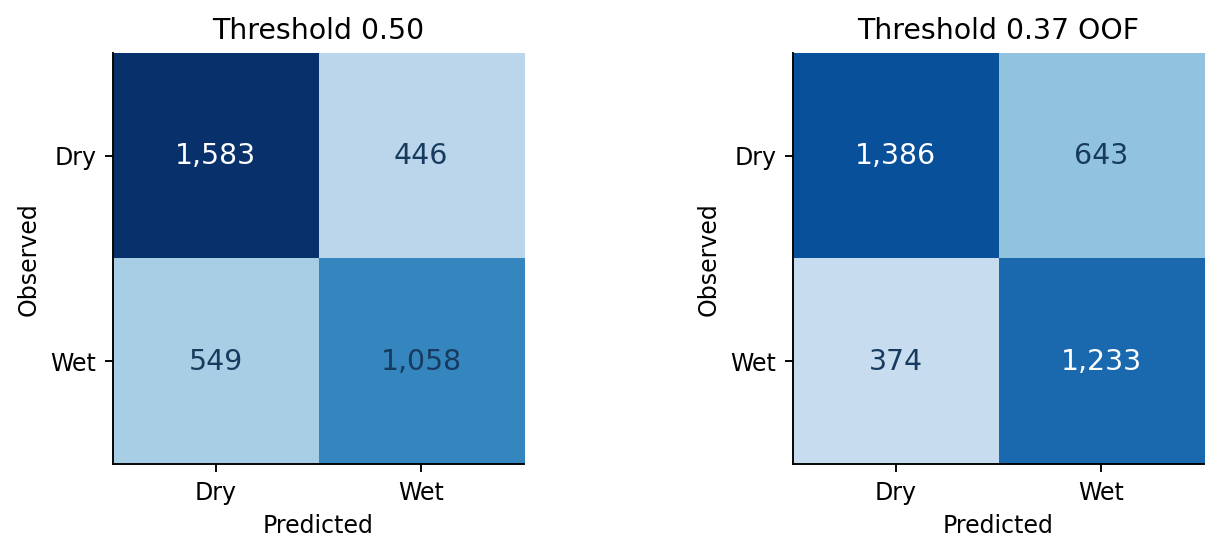

,Days,Wet rate,AUC,AP,Accuracy,Precision,Recall,Specificity,F1,Brier,TN,FP,FN,TP
Winter,886.0,0.5847,0.7475,0.7909,0.7077,0.7350,0.7819,0.6033,0.7577,0.1981,222.0,146.0,113.0,405.0
Spring,920.0,0.5152,0.7329,0.7331,0.6598,0.6825,0.6350,0.6861,0.6579,0.2116,306.0,140.0,173.0,301.0
Summer,920.0,0.1880,0.7420,0.4223,0.8283,0.5949,0.2717,0.9572,0.3730,0.1313,715.0,32.0,126.0,47.0
Autumn,910.0,0.4857,0.7739,0.7446,0.7088,0.7044,0.6900,0.7265,0.6971,0.1936,340.0,128.0,137.0,305.0


,1983–87,1988–92,1993–97,1998–02,2003–07,Mean AUC
Calendar,0.6778,0.6807,0.6466,0.6919,0.6706,0.6735
Calendar + today,0.7782,0.7724,0.7803,0.7756,0.7765,0.7766
Calendar + today + history,0.7810,0.7740,0.7804,0.7734,0.7770,0.7771


,AUC decrease
Recent history,-0.0004
Today temperature,0.0036
Annual season,0.0048
Today precipitation and status,0.0163


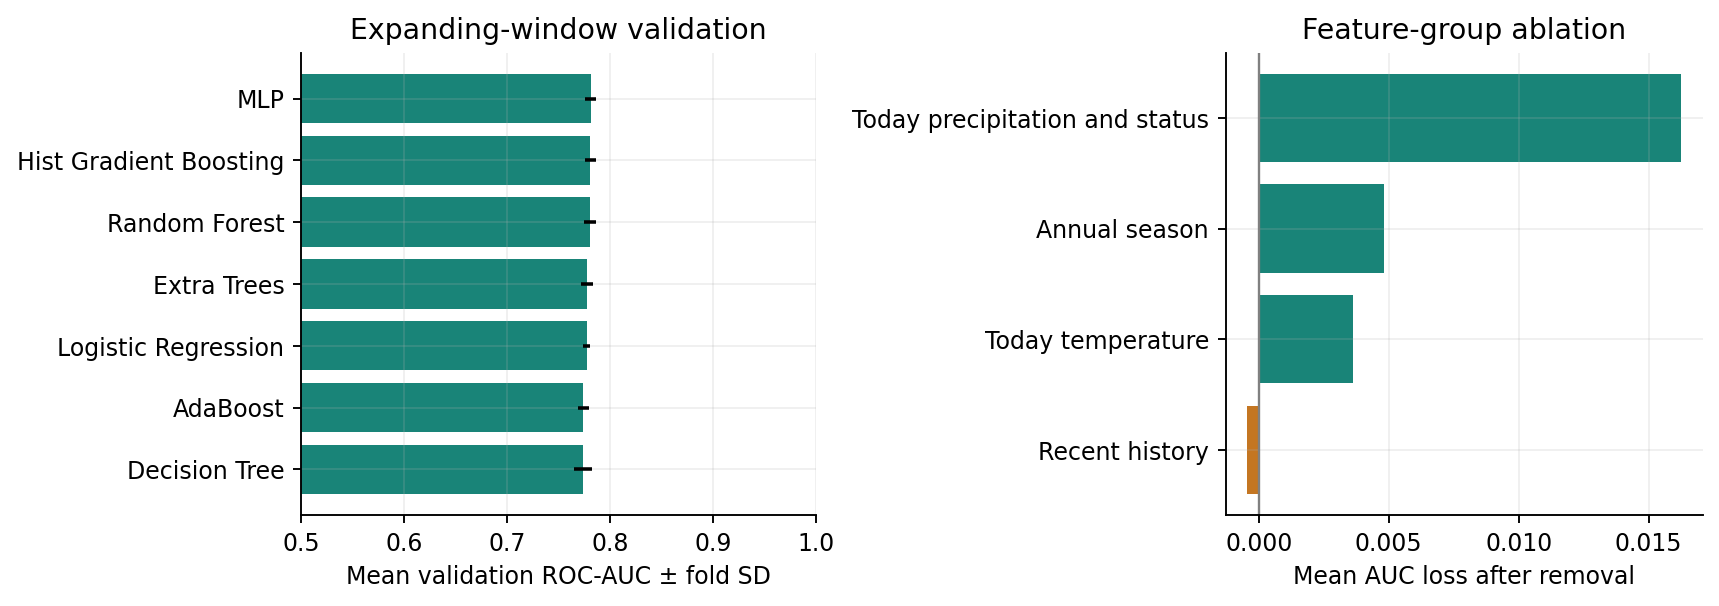

30일 블록 AUC 95% 구간: [0.7708610352006926, 0.8146265465436531]


In [6]:
oof=cv_predictions[chosen]; valid=np.isfinite(oof)
oof_y=train.y.to_numpy()[valid]; oof_p=oof[valid]
threshold_grid=np.arange(5,96)/100
costs=[2*np.sum((oof_y==1)&(oof_p<t))+np.sum((oof_y==0)&(oof_p>=t)) for t in threshold_grid]
idx=min(range(len(costs)),key=lambda i:(costs[i],round(abs(threshold_grid[i]-.5),8),threshold_grid[i]))
threshold=float(threshold_grid[idx]); final_prob=probabilities[chosen]
alternate=evaluate(test.y,final_prob,threshold)
operating=pd.DataFrame({'0.50':results.loc[chosen].to_dict(),f'{threshold:.2f} OOF':alternate}).T
operating['Cost (2FN+FP)']=2*operating.FN+operating.FP
show_table('thresholds',operating)
fig,ax=plt.subplots(1,2,figsize=(8,3.15),layout='constrained')
for (name,row),a in zip(operating.iterrows(),ax):
    mat=np.array([[row.TN,row.FP],[row.FN,row.TP]]).astype(int)
    a.imshow(mat,cmap='Blues',vmin=0,vmax=operating[['TN','FP','FN','TP']].to_numpy().max());a.grid(False)
    for i in range(2):
        for j in range(2): a.text(j,i,f'{mat[i,j]:,}',ha='center',va='center',color='white' if mat[i,j]>1200 else NAVY,fontsize=12)
    a.set(xticks=[0,1],yticks=[0,1],xticklabels=['Dry','Wet'],yticklabels=['Dry','Wet'],xlabel='Predicted',ylabel='Observed',title=f'Threshold {name}')
save_plot(fig,'fig05_confusion')
# 달력 순서에서 실제 목표를 아는 날만 선택하여 구간별 성능을 계산한다.
months = test.target_date.dt.month
seasons=np.select([months.isin([12,1,2]),months.isin([3,4,5]),months.isin([6,7,8])],['Winter','Spring','Summer'],default='Autumn')
season_rows={}
for season in ['Winter','Spring','Summer','Autumn']:
    mask=seasons==season
    season_rows[season]={'Days':int(mask.sum()),'Wet rate':float(test.y[mask].mean()),**evaluate(test.y[mask],final_prob[mask])}
season_table=pd.DataFrame(season_rows).T
show_table('seasons',season_table)

# 결측일을 제거하기 전의 달력 길이를 유지하고, 블록 추출 후 결측 목표를 제외한다.
calendar_index=pd.date_range(test.target_date.min(),test.target_date.max(),freq='D')
calendar_test=test.set_index('target_date').assign(score=final_prob).reindex(calendar_index)
arr=calendar_test[['y','score']].to_numpy()
N=len(arr); block=30; rng=np.random.default_rng(SEED); boot=[]
for _ in range(1000):
    starts=rng.integers(0,N,size=int(np.ceil(N/block)))
    sample=arr[((starts[:,None]+np.arange(block))%N).ravel()[:N]]
    sample=sample[np.isfinite(sample[:,0])]
    boot.append(roc_auc_score(sample[:,0],sample[:,1]))
ci=np.quantile(boot,[.025,.975]).tolist();print('30일 블록 AUC 95% 구간:',ci)

with threadpool_limits(limits=1):
    ablation_scores={'Calendar':validate('Logistic Regression',calendar)[0],
                     'Calendar + today':validate('Logistic Regression',current)[0],
                     'Calendar + today + history':cv_scores['Logistic Regression']}
    drop_groups={'Annual season':['season_sin','season_cos'],
        'Today precipitation and status':['precip_mm_today','rain_today'],
        'Today temperature':['max_c_today','min_c_today','range_c_today'],
        'Recent history':[c for c in all_cols if c not in current]}
    importance={name:float(cv.loc[chosen,'Mean AUC']-np.mean(validate(chosen,[c for c in all_cols if c not in group])[0])) for name,group in drop_groups.items()}
ablation=pd.DataFrame(ablation_scores,index=cv.columns[:5]).T
ablation['Mean AUC']=ablation.mean(axis=1)
show_table('ablation',ablation)
impact=pd.Series(importance,name='AUC decrease').sort_values()
show_table('feature_groups',impact.to_frame())
fig,ax=plt.subplots(1,2,figsize=(10,3.45),layout='constrained',gridspec_kw={'width_ratios':[1.08,1]})
rank=cv.sort_values('Mean AUC');ax[0].barh(rank.index,rank['Mean AUC']-.5,left=.5,xerr=rank.SD,color=TEAL);ax[0].set(xlim=(.5,1),xlabel='Mean validation ROC-AUC ± fold SD',title='Expanding-window validation')
ax[1].barh(impact.index,impact.values,color=[TEAL if x>=0 else AMBER for x in impact]);ax[1].axvline(0,color='gray',lw=1);ax[1].set(xlabel='Mean AUC loss after removal',title='Feature-group ablation')
save_plot(fig,'fig06_validation')

summary={'quality':quality,'train_n':len(train),'test_n':len(test),'test_wet':int(test.y.sum()),'train_wet':int(train.y.sum()),
         'chosen':chosen,'threshold':threshold,'threshold_cost_cv':int(costs[idx]),'default_cost_cv':int(costs[45]),
         'auc_ci':ci,'tail':tail,'features':all_cols,'next_rate':next_rate.to_dict(),
         'versions':{'python':sys.version.split()[0],'numpy':np.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'sklearn':sklearn.__version__}}
(OUT/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
pd.DataFrame({'target_date':test.target_date.to_numpy(),'observed':test.y.to_numpy(),'score':final_prob}).to_csv(OUT/'test_predictions.csv',index=False)
